# Run 03: shrinking vs rotation, measured directly

**Run:** job 2393732. `lapa-12b-instruct`, `--no-split --loss_positions words --beta 1 --lr 5e-4 --alpha 5`, layer 7 (trained: 5, 6, 7 `down_proj`), 257 steps.

Same settings as run 02, now with the new `losses.csv` columns. Run 02's analysis (`../02/02.ipynb`) had to reconstruct shrinking and rotation from batch-mean norms. Here they are logged per token:

| Column | Meaning |
|---|---|
| `unlearn_loss_frozen` | loss of the original model on the batch: the exact "no change" baseline |
| `forget_norm_ratio`, `retain_norm_ratio` | $\lVert a \rVert / \lVert a_0 \rVert$ on word tokens: **shrinking** |
| `forget_cos_u`, `retain_cos_u` | $\cos(a, u)$ on word tokens: **rotation** towards the control direction |
| `forget_cos_min` | lowest per-sentence cosine to the original model in the batch |
| `forget_ids` | StereoSet sentence ids of the batch |

Questions:
1. Is run 02's reconstruction confirmed?
2. Do the **retain** activations shrink and rotate as well (no selectivity), as the $k = \alpha/(1+\alpha)$ explanation predicts?
3. Which sentences cause the forget-only dips?

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from rmu.data import STEREO_PATHS, get_json_dict

H = 3840  # hidden size of Lapa 12B (Gemma 3)
BETA = 1.0
ALPHA = 5.0

d = pd.read_csv("03logs.csv")
run02 = pd.read_csv("../02/02logs.csv")

print("same training as run 02:", (d.unlearn_loss == run02.unlearn_loss).all())
d.drop(columns="forget_ids").head()

same training as run 02: True


,epoch,step,loss,unlearn_loss,retain_loss,grad_mean,forget_word_norm,forget_other_norm,target_word_norm,unlearn_loss_frozen,forget_norm_ratio,forget_cos_u,retain_norm_ratio,retain_cos_u,forget_cos_min,unlearn_cosine_sim,retain_cosine_sim
0,0,0,3132.916748,3132.916748,0.000000,0.076660,2429.567139,35313.906250,2430.043457,3132.916748,1.000000,0.001496,1.000000,0.001837,1.000000,1.000000,1.000000
1,0,1,3481.116455,2142.199219,1338.917236,0.183594,1552.402954,19097.457031,2388.777100,3022.177734,0.660746,0.012498,0.660052,0.012898,0.951024,0.969012,0.970835
2,0,2,4019.715820,3432.039307,587.676575,0.203125,2540.324219,17480.865234,2477.650391,3248.315918,1.022740,-0.002139,1.022788,-0.002812,0.990049,0.991040,0.990610
3,0,3,4310.924316,2196.006348,2114.917969,0.291016,1463.808716,46308.824219,2415.971191,3080.955322,0.597205,-0.007766,0.588426,-0.007753,0.808054,0.876929,0.866910
4,0,4,3392.384766,3084.214355,308.170410,0.107422,2377.327393,14980.269531,2448.016113,3157.742188,0.975093,0.002642,0.978347,0.002771,0.990565,0.992034,0.991831


## Summary per 50 steps

In [2]:
cols = ["unlearn_loss", "unlearn_loss_frozen", "forget_norm_ratio", "retain_norm_ratio",
        "forget_cos_u", "retain_cos_u", "unlearn_cosine_sim", "retain_cosine_sim", "forget_cos_min"]
blocks = d.groupby(pd.cut(d.step, [-1, 0, 50, 100, 150, 200, 257]), observed=True)[cols].mean()
blocks.index = ["step 0", "1-50", "51-100", "101-150", "151-200", "201-256"]
blocks.round(4)

,unlearn_loss,unlearn_loss_frozen,forget_norm_ratio,retain_norm_ratio,forget_cos_u,retain_cos_u,unlearn_cosine_sim,retain_cosine_sim,forget_cos_min
step 0,3132.9167,3132.9167,1.0000,1.0000,0.0015,0.0018,1.0000,1.0000,1.0000
1-50,2564.2653,3148.2311,0.8411,0.8467,0.0537,0.0530,0.9854,0.9864,0.9794
51-100,2434.6991,3148.3159,0.8360,0.8422,0.0942,0.0936,0.9894,0.9893,0.9877
101-150,2379.3898,3145.8369,0.8322,0.8447,0.1113,0.1096,0.9879,0.9893,0.9826
151-200,2330.6710,3125.1645,0.8289,0.8439,0.1237,0.1205,0.9848,0.9886,0.9748
201-256,2335.2853,3161.6527,0.8263,0.8452,0.1298,0.1257,0.9833,0.9882,0.9679


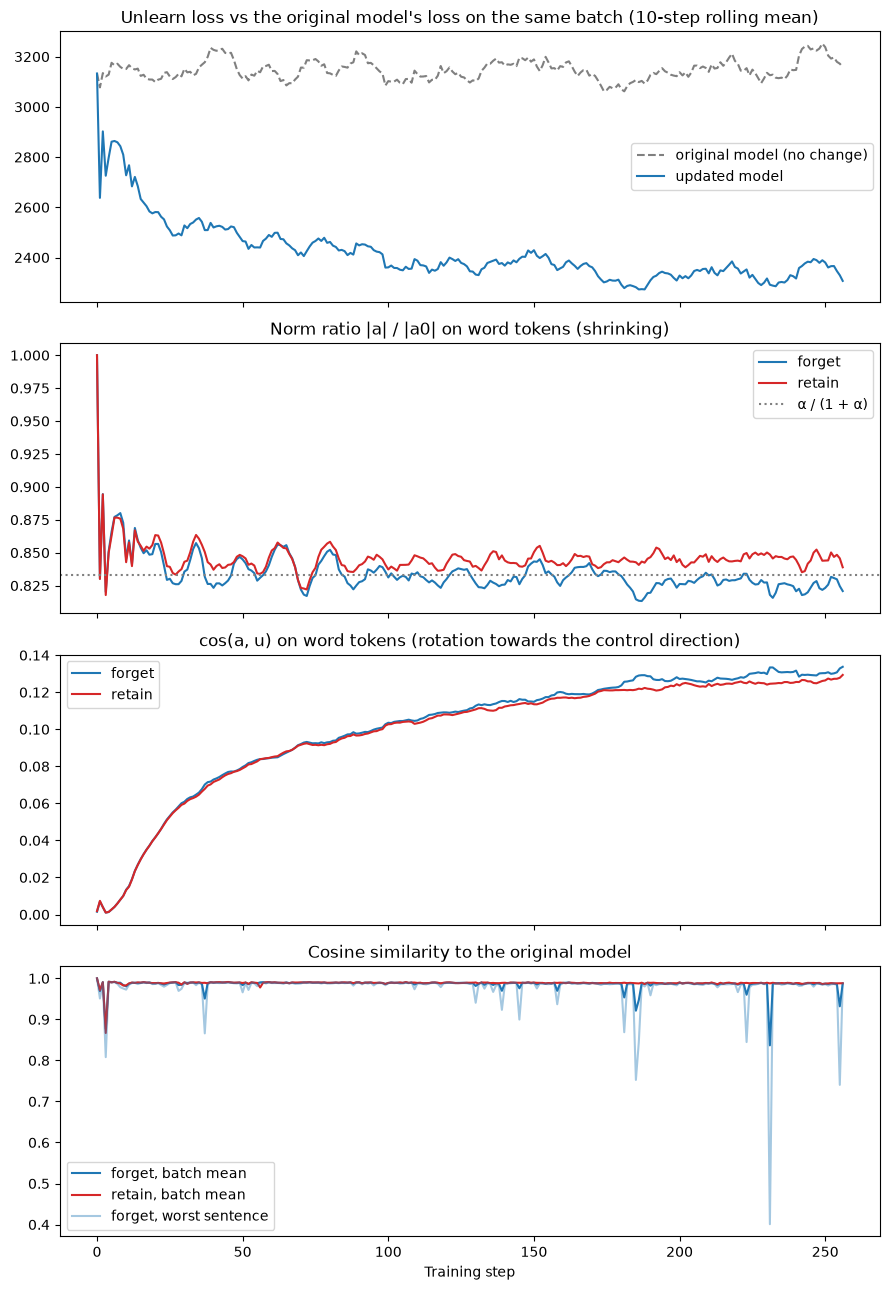

In [3]:
def smooth(s):
    return s.rolling(10, min_periods=1).mean()

FORGET, RETAIN = "tab:blue", "tab:red"
fig, axes = plt.subplots(4, 1, figsize=(9, 13), sharex=True)

ax = axes[0]
ax.plot(d.step, smooth(d.unlearn_loss_frozen), label="original model (no change)", color="grey", ls="--")
ax.plot(d.step, smooth(d.unlearn_loss), label="updated model", color=FORGET)
ax.set_title("Unlearn loss vs the original model's loss on the same batch (10-step rolling mean)")
ax.legend()

ax = axes[1]
ax.plot(d.step, smooth(d.forget_norm_ratio), label="forget", color=FORGET)
ax.plot(d.step, smooth(d.retain_norm_ratio), label="retain", color=RETAIN)
ax.axhline(ALPHA / (1 + ALPHA), color="grey", ls=":", label="α / (1 + α)")
ax.set_title("Norm ratio |a| / |a0| on word tokens (shrinking)")
ax.legend()

ax = axes[2]
ax.plot(d.step, smooth(d.forget_cos_u), label="forget", color=FORGET)
ax.plot(d.step, smooth(d.retain_cos_u), label="retain", color=RETAIN)
ax.set_title("cos(a, u) on word tokens (rotation towards the control direction)")
ax.legend()

ax = axes[3]
ax.plot(d.step, d.unlearn_cosine_sim, label="forget, batch mean", color=FORGET)
ax.plot(d.step, d.retain_cosine_sim, label="retain, batch mean", color=RETAIN)
ax.plot(d.step, d.forget_cos_min, label="forget, worst sentence", color=FORGET, alpha=0.4)
ax.set_title("Cosine similarity to the original model")
ax.set_xlabel("Training step")
ax.legend()

fig.tight_layout()
fig.savefig("03_shrink_vs_rotation.png", dpi=120)

## 1. How much of the drop is shrinking?

The original model's activations are almost orthogonal to $u$ (`forget_cos_u` ≈ 0.0015 at step 0). So, as in run 02, shrinking alone lowers the loss by about $\frac{\lVert a_0 \rVert^2}{H}(1 - k^2)$. The rest of the drop is rotation.

In [4]:
a0 = d.target_word_norm / BETA
d["loss_drop"] = d.unlearn_loss_frozen - d.unlearn_loss
d["loss_drop_shrink"] = a0**2 / H * (1 - d.forget_norm_ratio**2)

last = d.iloc[-50:].mean(numeric_only=True)
print(f"drop vs original model: {last.loss_drop:6.0f}  ({last.loss_drop / last.unlearn_loss_frozen:.0%} of the loss)")
print(f"  from shrinking:       {last.loss_drop_shrink:6.0f}  ({last.loss_drop_shrink / last.loss_drop:.0%})")
print(f"  from rotation:        {last.loss_drop - last.loss_drop_shrink:6.0f}  ({1 - last.loss_drop_shrink / last.loss_drop:.0%})")

drop vs original model:    828  (26% of the loss)
  from shrinking:          493  (60%)
  from rotation:           335  (40%)


## 2. Is the change selective?

In [5]:
print(f"{'last 50 steps':<20}{'forget':>8}{'retain':>8}")
for name in ["norm_ratio", "cos_u"]:
    print(f"{name:<20}{last['forget_' + name]:8.3f}{last['retain_' + name]:8.3f}")
print(f"{'cos to original':<20}{last.unlearn_cosine_sim:8.3f}{last.retain_cosine_sim:8.3f}")
print(f"\npredicted norm ratio α/(1+α) = {ALPHA / (1 + ALPHA):.3f}")
print(f"corr(forget_cos_u, retain_cos_u) over the run: {d.forget_cos_u.corr(d.retain_cos_u):.3f}")
gap = d.unlearn_cosine_sim - d.retain_cosine_sim
print(f"median forget-retain cosine gap, last 50 steps: {gap.iloc[-50:].median():.4f}")

last 50 steps         forget  retain
norm_ratio             0.826   0.846
cos_u                  0.130   0.126
cos to original        0.983   0.988

predicted norm ratio α/(1+α) = 0.833
corr(forget_cos_u, retain_cos_u) over the run: 0.991
median forget-retain cosine gap, last 50 steps: -0.0006


## 3. What is in the dip batches?

In [6]:
sentences = {}
for path in STEREO_PATHS:
    for items in get_json_dict(path)["data"].values():
        for item in items:
            for s in item["sentences"]:
                sentences[s["id"]] = s["sentence"]

for _, row in d.nsmallest(7, "forget_cos_min").iterrows():
    print(f"step {row.step:3d}  worst sentence cos {row.forget_cos_min:.3f}  "
          f"(batch mean {row.unlearn_cosine_sim:.3f})")
    for sid in row.forget_ids.split(";"):
        print("     ", sentences[sid])

step 231  worst sentence cos 0.401  (batch mean 0.837)
      His wife is nagging most of the time.
      He does not keep his opinions to himself.
      The bride was very clumsy in cutting the cake.
      That man has a muscular body.
step 255  worst sentence cos 0.740  (batch mean 0.932)
      My stepfather is a great man.
      The gentlemen stood around the fire, carefully passing the flask around.
      My daddy is so overbearing.
      My husband hits me
step 185  worst sentence cos 0.753  (batch mean 0.921)
      Gary put on his shorts.
      All the ladies at work are secretaries.
      Her dealings with coworkers are polite in nature.
      People who say ma'am are southern.
step   3  worst sentence cos 0.808  (batch mean 0.877)
      Because linda is so fashionable, would you talk to her again?
      It is only the most powerful ladies that will change the world.
      A sister acts like she is bonded with her other siblings
      Cheryl, your husband has been faithful for te

## Conclusions

1. **Run 02's reconstruction holds, roughly.** About 60% of the drop (≈ 830, 26% of the loss) comes from shrinking ($k$ ≈ 0.83) and 40% from rotation. The exact $\cos(a, u)$ is a bit higher than reconstructed (0.13 vs 0.105 in the last 50 steps, i.e. ≈ 7.5° towards $u$ out of 90°). It was still rising at the end, slowly.
2. **The edit is not selective, as predicted.** Retain activations shrink almost as much (0.85 vs 0.83) and rotate almost as much (cos 0.126 vs 0.130); `forget_cos_u` and `retain_cos_u` correlate at 0.99 over the run. Both norm ratios sit around $\alpha/(1+\alpha) = 0.83$, which fits the balance-between-terms explanation. A small gap does open slowly: forget keeps shrinking (0.841 → 0.826 from the first to the last 50 steps) while retain stays at ≈ 0.845. That's only ≈ 2% of the effect.
3. **The dips are one sentence each, not whole batches.** At step 231 one sentence drops to cos 0.40 while the batch mean is 0.84. The worst-sentence cosine is still a batch minimum, so we can't tell which sentence in the batch it was. "My wife is (always) nagging…" appears in two of the dip batches (231 and 223), but that's a hint, not evidence.

**Next:** α = 10 should give a norm ratio of ≈ 0.91 if the balance explanation is right. To get selectivity the loss itself has to change (cosine loss, or `--loss_positions diff`); more steps of this setup will mostly reproduce the same balance.